In [1]:

# Initialize Otter
import otter
grader = otter.Notebook("HW_1a_numpy_and_plotting.ipynb")

# HW 1: Statistical analysis of data using numpy and matplotlib

Slides: (https://docs.google.com/presentation/d/1ef0msC9XIT37_Yg94Cf4TL9VBgbIIfkKik8jgshskjE/edit?usp=sharing)

Please do lab 1 before starting the first part of this homework and lab 2 before the second part. This homework will continue in Homework 1b.

In this homework the focus is on code *design*. Most of the functionality of the code will be what you did in the labs. I don't expect you to do the code design; I've provided that. Just pay attention to how a couple of code structuring tools (functions, dictionaries) can make your code a little more re-usable, cleaner, and less prone to error. 

Learning to *read* code is also as important as *writing* code. This is (hopefully) a gentle introduction to using/interacting with more advanced concepts/syntax/semantics. 

By the end of the homework assignment, you will have written a method for categorizing the type of a given motion (snap, high five, or clap) and determined its accuracy on the provided dataset.

## Week 1, problem 0: Setting up libraries

GUIDES: Import the libraries that you will need (numpy, json, matplotlib, os)

In [2]:
# GUIDES: put the numpy, os, json, and matplotlib imports here so you can use those libraries (see the tops of Labs 1-3)
#  Parts 1 and 2 only need numpy, os and json. Part 3 needs matplotlib; you can either look at lab 3 and copy the import now or do
#  it later
import numpy as np
import json as json

import os

import matplotlib.pyplot as plt
%matplotlib inline

In [3]:
grader.check("libraries")

libraries results: All test cases passed!

## Week 1, problem 1: Read data set and description

In Lab 1, you read in a few CSV files, where each contained the data from a single motion from a single person. In this problem, you will read in a single CSV file that contains a full dataset containing multiple types of motions from multiple people ("subjects") done multiple times.

The data is stored in `Data/full_dataset.csv`, and is described in `Data/full_dataset_data_description.json`. Note how `full_dataset_data_description.json` is different from `data_description.json`; there are three new data channels:

* Subject number: Identifies the person ("human subject") performing the motion. There are 10 different people in the data set.
* Run number: Each person did each motion 10 times, and this number identifies each unique run of the motion.
* Motion type: Contains the motion ID of the motion performed, corresponding to a high five, snap, or clap.

Almost all of this homework involves copying the code you wrote in Lab 1 but reading these two different files.

A reminder that capitalization matters for file names - data/full_dataset.csv is NOT the same as Data/full_dataset.csv. 

In [4]:
# GUIDES: Read in `Data/full_dataset.csv` into `full_dataset`, and `Data/full_dataset_data_description.json` into `data_description`.

full_dataset = np.loadtxt("Data/full_dataset.csv", delimiter=',')
with open("Data/full_dataset_data_description.json", "r") as fp:
        data_description = json.load(fp)

In [5]:
grader.check("read_data")

read_data results: All test cases passed!

## Week 1, problem 2: Filtering data set

In this homework, you will need to perform operations on individual motions identified by a specific subject, motion type, and run number. For this part, write code to extract the fourth snap performed by subject three. We will later turn this into a function.

In [6]:
# Numeric ids to indicate hand motion type from Lab 1
clap_id = 1
high_five_id = 2
snap_id = 3

# Hardcoded column numbers for this data to make the code easier; normally, you would extract this from
# full_dataset_data_description.json.
timestamp_col = 0
subject_number_col = 13
run_number_col = 14
motion_id_col = 15

In [7]:
# GUIDES: Extract a numpy array containing the rows for the fourth snap performed by subject three.
# Hint: You can apply three different boolean filters to whittle down the data set, 
#  use np.all() to combine the filters into one filter, or use logical and.
# Reminder to use the variable snap_id (defined above) when searching for rows that are snaps

refined_rows = (
    (full_dataset[:, subject_number_col] == 3) 
    & (full_dataset[:, motion_id_col] == snap_id) 
    & (full_dataset[:, run_number_col] == 4)
)
s3s4_snap_data = full_dataset[refined_rows]
print(s3s4_snap_data.shape)

(92, 16)


In [8]:
grader.check("filter_data_set")

filter_data_set results: All test cases passed!

## Week 1, problem 3: Calculate RMS

In this homework, you will be writing code to determine which motion a person is performing. One common way to differentiate between different motion types is with well chosen summary statistics of the data. This can include statistics on individual axes, as well as statistics that combine multi-dimensional data (e.g., the x, y, and z data from accelerometers).

We will use the root mean square (RMS) of the accelerometer data as one such summary statistic. RMS is particularly useful to us here since it is an excellent information stream for detecting contact (such as impact between hands, collisions between fingers as you snap), even if hand orientation is not perfectly consistent.

For this problem, you will write a function to calculate the RMS of each row in an array, and use it to calculate the RMS of two specific data channels for the entire data set.

In [9]:
# GUIDES: Copy the function get_channel_data from lab 2.
def get_channel_data(all_data, index_offset, n_dims):
    """ Get the data for just one channel (e.g., right hand accelerometer)
    @param all_data - numpy array containing data from one (or more) files
    @param index_offset - the column to begin getting data from
    @param n_dims - number of dimensions for the data channel
    @return Returned array should be: number of rows in all_data X n_dims"""

    channel_data = all_data[:, index_offset: index_offset + n_dims]
    return channel_data

In [10]:
# GUIDES: Copy the function get_descriptor from lab 2.
def get_descriptor(data_description, name):
    """ Search through data_description to find the dictionary with name "name"
    @param name - The name of the data channel to look for. 
    @return the dictionary that has name as the 'name' key"""
    
    list_of_dict = data_description["data_channels"]
    for item in list_of_dict:
        if item["name"] == name:
            return item
        else:
            pass

In [11]:
# definition of RMS (Root Mean Squared): sqrt( mean(sum_x x^2) )
def rms(in_data):
   """ Calculate the root mean square of each row in in_data.
   @param in_data - A 2-dimensional numpy array
   @return An n rows by 1 column numpy array containing the RMS of each row in in_data.
   """
   # GUIDES: Fill in this function.
   # Hint: Use numpy functions to operate on the entire array at once rather than
   # iterate through each row.
   return np.sqrt(np.mean(in_data**2, axis=1, keepdims=True))

In [12]:
# Check that the rms function works as expected
test_array = np.array([[1, 2, 3], [4, 5, 6]])

# Calculation for first row (reminder, mean is sum of values divided by number of values)
first_row_rms = np.sqrt((1 * 1 + 2 * 2 + 3 * 3) / 3)
print(first_row_rms)
test_array_rms = rms(test_array)
assert(np.isclose(test_array_rms[0], first_row_rms))
assert(np.isclose(test_array_rms[1], 5.06622805))

2.160246899469287


In [13]:
# GUIDES: Use rms, full_dataset, get_descriptor, and get_channel_data to calculate the RMS of left hand accelerometer and right hand accelerometer for the entire data set.

lh_accelerometer_descriptor = get_descriptor(data_description, "Left hand accelerometer")
lh_accelerometer_data = get_channel_data(full_dataset, index_offset=lh_accelerometer_descriptor["index_offset"], n_dims=lh_accelerometer_descriptor["dimensions"])
lh_accelerometer_rms_check = rms(lh_accelerometer_data)

rh_accelerometer_descriptor = get_descriptor(data_description, "Right hand accelerometer")
rh_accelerometer_data = get_channel_data(full_dataset, index_offset=rh_accelerometer_descriptor["index_offset"], n_dims=rh_accelerometer_descriptor["dimensions"])
rh_accelerometer_rms_check = rms(rh_accelerometer_data)

In [14]:
grader.check("calculate_rms")

calculate_rms results: All test cases passed!

## Week 2, problem 1: Function for filtering data set

Take the code from Week 1 problem 2 and turn it into a re-usable function.

In [15]:
def filter_data_set(data, subject_number, run_number, motion_id):
    """ Filters a data set to a specific run of a specific motion type from a specific subject.
    @param data - The full dataset, containing multiple motion runs from multiple people.
    @return Just the rows for the given subject number, run number, and motion id.
    """
    refined_rows = (
    (data[:, subject_number_col] == subject_number) 
    & (data[:, motion_id_col] == motion_id) 
    & (data[:, run_number_col] == run_number)
    )
    s3s4_snap_data = data[refined_rows]
    return s3s4_snap_data

In [16]:
# GUIDES: Write a test function. Call filter_data_set with the values for s3s4_snap_data,
#   i.e., subject number 3, run number 4, snap data
# And check that the resulting data is the same as s3s4_snap_data
test_s3s4 = filter_data_set(full_dataset, 3, 4, snap_id)

foo = filter_data_set(full_dataset, 3, 4, snap_id)

In [17]:
grader.check("filter_function")

filter_function results: All test cases passed!

## Week 2, problem 2: Finding peak and valley of a data channel

Often, the maximum and minimum value of a data channel are informative as further summary statistics, in addition to being helpful for pinpointing the occurrence of key events such as moments of hand contact in the recorded data. The difference between these maximum and minimum values can be helpful, too, as you try to understand the range of your data. 

For this problem, you will write a function that locates the first row containing a specific value, and then use it to find the peak and valley of a data channel. The function will be very similar to the optional section of lab 2.

While data can have multiple peaks and valleys, for simplicity we will only look at the first location with the maximum and minimum value for the data channel.

A reminder that there is a tutorial for using **np.where**.

In [18]:
def find_row_with_value(data, value):
    """ Locates the first index of data containing value.
    @param data - A 1-d array containing data.
    @param value - A specific value to look for in data.
    @return The index of value within data, or -1 if value is not found.
    """
    # GUIDES: Write this function. See the optional section of lab 2 for hints on how to do this.
    b_is_value = data == value
    indices = np.where(b_is_value)
    if len(indices) == 0:
        return -1
    return indices[0][0]



In [19]:
# Simple test code for your function to help debug issues.
find_row_with_value_test_array = np.array([6, 7, 8, 7, 5])

assert(find_row_with_value(find_row_with_value_test_array, 6) == 0)
assert(find_row_with_value(find_row_with_value_test_array, 7) == 1)
assert(find_row_with_value(find_row_with_value_test_array, 5) == 4)

In [20]:
# GUIDES: Find peak and valley of z axis of the right hand accelerometer in s3s4_snap_data
# Hint: You can use get_channel_data to extract just the rh accelerometer channel from s3s4_snap_data.

rh_accelerometer_descriptor = get_descriptor(data_description, "Right hand accelerometer")
s3s4_snap_rh_accelerometer_data = get_channel_data(s3s4_snap_data, index_offset=rh_accelerometer_descriptor["index_offset"], n_dims=rh_accelerometer_descriptor["dimensions"])
s3s4_snap_rh_accelerometer_z_data = s3s4_snap_rh_accelerometer_data[:, 2]

s3s4_snap_rh_accelerometer_z_min = np.min(s3s4_snap_rh_accelerometer_z_data)
s3s4_snap_rh_accelerometer_z_max = np.max(s3s4_snap_rh_accelerometer_z_data)

z_is_min = s3s4_snap_rh_accelerometer_z_data == s3s4_snap_rh_accelerometer_z_min
min_z_indices = np.where(z_is_min)[0][0]
z_is_max = s3s4_snap_rh_accelerometer_z_data == s3s4_snap_rh_accelerometer_z_max
max_z_indices = np.where(z_is_max)[0][0]

s3s4_snap_rh_accelerometer_z_min_index = min_z_indices
s3s4_snap_rh_accelerometer_z_max_index = max_z_indices

In [21]:
grader.check("peak_and_valley")

peak_and_valley results: All test cases passed!

## Week 2, problem 3: Graph RMS for each motion type

We have the full data set, a way to filter it, and the ability to calculate RMS for a given data channel. Let's combine these abilities and graph the left hand and right hand accelerometer RMS for a single clap, snap, and high five. After that, we can take a step back and observe how the graph differs between motion types.

This question has a manually-graded portion; if your plots are incorrect you will have points deducted on Gradescope. See slides for what the plots should look like.

In [22]:
# GUIDES: Copy plot_function from Lab 3.
def plot_function(axs, ts, data, channel_info, dim_name):
    """ Plot all of the dimensions for a given channel
    @param axs - the place to plot in
    @param ts - the time steps to use
    @param data - the numpy array from the csv file
    @param channel_info - a dictionary with the channel info, e.g. "name" and "units"
    @param dim_name - the name of the dimension being called
    @returns - nothing"""

    axs.plot(ts, data)
    axs.set_title(channel_info[dim_name]['name'])
    axs.set_xlabel(channel_info['Timestamp']['units'])
    axs.set_ylabel(channel_info[dim_name]['units'])
    
    fig.tight_layout()
    pass

In [23]:
# GUIDES: Create a plot with 3 rows and 2 columns. Plots in the left column contain the RMS of the left hand accelerometer,
# and plots in the right column contain the RMS of the right hand accelerometer. The first row contains graphs for a snap,
# the second row a clap, and the third row a high five. You can plot any single snap, clap, or high five in the data set.

# Use the variables below when filtering the data.
# For the final submitted graph, please use subject 6 run 3.
# But prior to submission, feel free to explore the data
# by looking at graphs for other subjects/runs!

snap_subject_number = 6
snap_run_number = 3

clap_subject_number = 6
clap_run_number = 3

high_five_subject_number = 6
high_five_run_number = 3

# Hint: For calculating and using RMS, you have two options:
#
#   I've copied `full_dataset` into `all_data` for you
# * Add two columns to the end of `all_data` containing the RMS of the left hand accelerometer and the right hand accelerometer
#   for every row in the data set, and then filter `all_data` to the specific subject number, run number, and motion type.
#   You can use `np.append` to add these columns.
#
# OR
#
# * Filter `all_data` to the specific subject number, run number, and motion type, and then calculate the RMS of the left hand
#   accelerometer and right hand accelerometer for that motion in separate numpy arrays.

all_data = np.copy(full_dataset)
print(all_data.shape)


(31502, 16)


In [24]:
ts_descriptor = get_descriptor(data_description, "Timestamp")

filtered_snap_data = filter_data_set(all_data, snap_subject_number, snap_run_number, snap_id)
ts_snap = get_channel_data(filtered_snap_data, index_offset=ts_descriptor["index_offset"], n_dims=ts_descriptor["dimensions"])
filtered_clap_data = filter_data_set(all_data, clap_subject_number, clap_run_number, clap_id)
ts_clap = get_channel_data(filtered_clap_data, index_offset=ts_descriptor["index_offset"], n_dims=ts_descriptor["dimensions"])
filtered_high_five_data = filter_data_set(all_data, high_five_subject_number, high_five_run_number, high_five_id)
ts_high_five = get_channel_data(filtered_high_five_data, index_offset=ts_descriptor["index_offset"], n_dims=ts_descriptor["dimensions"])


lh_accelerometer_descriptor = get_descriptor(data_description, "Left hand accelerometer")
lh_accelerometer_snap_data = get_channel_data(filtered_snap_data, index_offset=lh_accelerometer_descriptor["index_offset"], n_dims=lh_accelerometer_descriptor["dimensions"])
lh_snap_rms_data = rms(lh_accelerometer_snap_data)
lh_accelerometer_clap_data = get_channel_data(filtered_clap_data, index_offset=lh_accelerometer_descriptor["index_offset"], n_dims=lh_accelerometer_descriptor["dimensions"])
lh_clap_rms_data = rms(lh_accelerometer_clap_data)
lh_accelerometer_high_five_data = get_channel_data(filtered_high_five_data, index_offset=lh_accelerometer_descriptor["index_offset"], n_dims=lh_accelerometer_descriptor["dimensions"])
lh_high_five_rms_data = rms(lh_accelerometer_high_five_data)

rh_accelerometer_descriptor = get_descriptor(data_description, "Right hand accelerometer")
rh_accelerometer_snap_data = get_channel_data(filtered_snap_data, index_offset=rh_accelerometer_descriptor["index_offset"], n_dims=rh_accelerometer_descriptor["dimensions"])
rh_snap_rms_data = rms(rh_accelerometer_snap_data)
rh_accelerometer_clap_data = get_channel_data(filtered_clap_data, index_offset=rh_accelerometer_descriptor["index_offset"], n_dims=rh_accelerometer_descriptor["dimensions"])
rh_clap_rms_data = rms(rh_accelerometer_clap_data)
rh_accelerometer_high_five_data = get_channel_data(filtered_high_five_data, index_offset=rh_accelerometer_descriptor["index_offset"], n_dims=rh_accelerometer_descriptor["dimensions"])
rh_high_five_rms_data = rms(rh_accelerometer_high_five_data)

[]

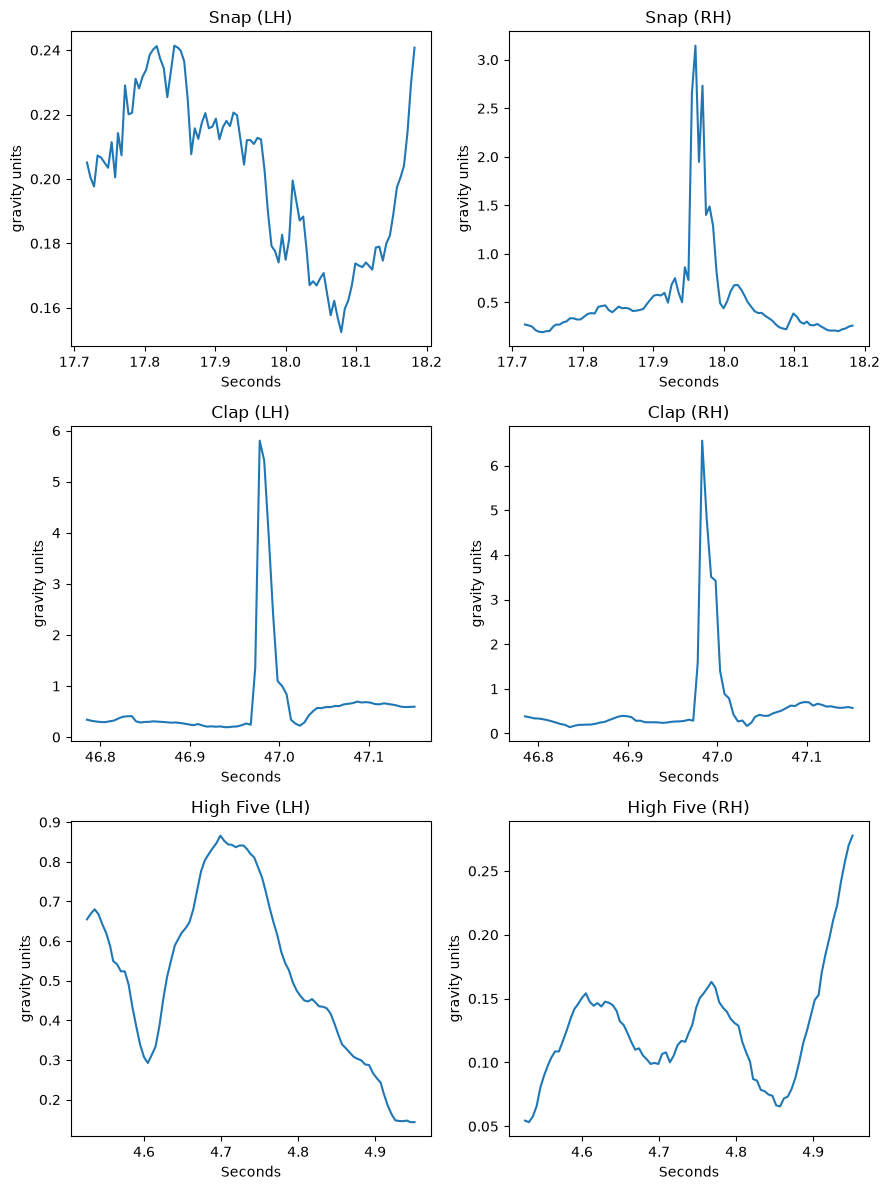

In [25]:
# Plot size
nrows = 3
ncols = 2
fig, axs = plt.subplots(nrows, ncols, figsize=(9, 12))

# GUIDES: Make the plot
# Put left hand in the first column, right hand in the second column.
# Hint: To use plot_function with your new "rms" data channel, you will need to make a
# dictionary for its descriptor with "name" and "units" entries.
# Note: The time values in the plots in the slides are divided by 1,000
# sl, sr, cl, cr, hfl, hfr
channel_info = {
    "Timestamp": {
        "units": "Seconds"
    },
    "Left hand snap rms": {
        "name": "Snap (LH)",
        "units": "gravity units",
    },
    "Right hand snap rms": {
        "name": "Snap (RH)",
        "units": "gravity units"
    },
    "Left hand clap rms": {
        "name": "Clap (LH)",
        "units": "gravity units"
    },
    "Right hand clap rms": {
        "name": "Clap (RH)",
        "units": "gravity units"
    },
    "Left hand high five rms": {
        "name": "High Five (LH)",
        "units": "gravity units"
    },
    "Right hand high five rms": {
        "name": "High Five (RH)",
        "units": "gravity units"
    },
}

#call plot function and plot 
plot_function(axs=axs[0,0], ts=ts_snap/1000, data=lh_snap_rms_data, channel_info=channel_info, dim_name='Left hand snap rms')
plot_function(axs=axs[0,1], ts=ts_snap/1000, data=rh_snap_rms_data, channel_info=channel_info, dim_name='Right hand snap rms')
plot_function(axs=axs[1,0], ts=ts_clap/1000, data=lh_clap_rms_data, channel_info=channel_info, dim_name='Left hand clap rms')
plot_function(axs=axs[1,1], ts=ts_clap/1000, data=rh_clap_rms_data, channel_info=channel_info, dim_name='Right hand clap rms')
plot_function(axs=axs[2,0], ts=ts_high_five/1000, data=lh_high_five_rms_data, channel_info=channel_info, dim_name='Left hand high five rms')
plot_function(axs=axs[2,1], ts=ts_high_five/1000, data=rh_high_five_rms_data, channel_info=channel_info, dim_name='Right hand high five rms')


fig.tight_layout()
plt.plot()


In [26]:
# Manual grade
print("")

In [27]:
grader.check("graph_rms")

graph_rms results: All test cases passed!

## Hours and collaborators
Required for every assignment - fill out before you hand-in.

Listing names and websites helps you to document who you worked with and what internet help you received in the case of any plagiarism issues. You should list names of anyone (in class or not) who has substantially helped you with an assignment - or anyone you have *helped*. You do not need to list TAs.

Listing hours helps us track if the assignments are too long.

In [28]:
import os

# List of names (creates a set)
worked_with_names = {"By Myself"}
# List of URLS FA26 (creates a set)
websites = {"https://stackoverflow.com/questions/3877491/deleting-rows-in-numpy-array", "https://stackoverflow.com/questions/40927156/what-is-the-role-of-keepdims-in-numpy-python"}
# Approximate number of hours, including lab/in-class time
hours = 12

# VS Code stores the path in a special global variable
if '__vsc_ipynb_file__' in globals():
    notebook_path = globals()['__vsc_ipynb_file__']
    notebook_name = os.path.basename(notebook_path)
    json_name = notebook_name[:-6] + "_source.json"
    if not os.path.exists(json_name):
        print(f"Could not find the json file {json_name}; make sure the required VSCode extension is installed and running")


In [29]:
grader.check("hours_collaborators")

hours_collaborators results: All test cases passed!

### To submit

- Do a restart then run all to make sure everything runs ok
- Remove excessive print statements - don't make us search through pages of numbers to find your plots
- Save the file
- Submit this .ipynb file and .json file through gradescope, HWK1 numpy and Plotting
- You do NOT need to submit the files in the Data directory - we will supply those

If the Gradescope autograder fails, please check here first for common reasons for it to fail
    https://docs.google.com/presentation/d/1tYa5oycUiG4YhXUq5vHvPOpWJ4k_xUPp2rUNIL7Q9RI/edit?usp=sharing

Most likely failure for this assignment is not naming the data directory and files correctly; capitalization matters for the Gradescope grader. 